# Smart Tagging: events, tags and distributions

This notebook explores `BAR-ATH_tactical_smart_tagging.xml` locally. Each row represents an automatically generated tactical interval—not a possession label and not human ground truth.

The analysis covers event codes, teams, set-piece types, interval durations, missing tag values and timing across the match.

> Keep notebook outputs local and clear them before committing.

In [1]:
from pathlib import Path
import os
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'games.py').exists() and (candidate / 'DATA.md').exists():
            return candidate
    raise FileNotFoundError('Could not find repository root')

ROOT = find_repo_root()
DATA_ROOT = Path(os.environ.get('MTAH_DATA_DIR', ROOT / 'data'))
FILENAME = 'BAR-ATH_tactical_smart_tagging.xml'
candidates = [DATA_ROOT / 'tactical' / FILENAME, DATA_ROOT / FILENAME]
PATH = next((p for p in candidates if p.exists()), None)
if PATH is None:
    raise FileNotFoundError(f'Could not find {FILENAME} in {candidates}')
FPS = 25
print('Reading:', PATH)

Reading: c:\Users\kiera\Desktop\LamineLmaoHackathon (Initial Repository)\TIKI-DATA\data\BAR-ATH_tactical_smart_tagging.xml


## 1. Convert the XML into a table

The XML stores one `instance` per interval. Tag groups vary by event type, so they are expanded into optional DataFrame columns.

In [2]:
def parse_smart_tagging(path):
    rows = []
    root = ET.parse(path).getroot()
    for instance in root.iter('instance'):
        start_s = float(instance.findtext('start'))
        end_s = float(instance.findtext('end'))
        row = {
            'code': instance.findtext('code'),
            'start_s': start_s,
            'end_s': end_s,
            'duration_s': end_s - start_s,
            'start_frame': int(round(start_s * FPS)),
            'end_frame': int(round(end_s * FPS)),
        }
        for label in instance.findall('label'):
            group = label.findtext('group')
            value = label.findtext('text')
            if group:
                row[group] = value
        rows.append(row)
    return pd.DataFrame(rows).sort_values('start_s').reset_index(drop=True)

events = parse_smart_tagging(PATH)
print(f'{len(events):,} intervals; {len(events.columns)} columns')
display(events.head(12))

638 intervals; 12 columns


,code,start_s,end_s,duration_s,start_frame,end_frame,Team,Type,Half,Max Players in the box,Side,Direction of ball entry
0,BALL IN FINAL THIRD,442.76,513.60,70.84,11069,12840,Atletic Club,NaN,1st Half,4,Central,NaN
1,LONG BALL,443.40,454.76,11.36,11085,11369,Atletic Club,NaN,1st Half,NaN,NaN,NaN
2,SET PIECES,443.88,448.88,5.00,11097,11222,N/A,Kick Off (Start),1st Half,NaN,NaN,NaN
3,DEFENDING IN MIDDLE THIRD,448.16,480.84,32.68,11204,12021,Barcelona,NaN,1st Half,NaN,NaN,NaN
4,PROGRESSION,448.16,480.84,32.68,11204,12021,Atletic Club,NaN,1st Half,NaN,NaN,NaN
5,PLAYERS IN THE BOX,448.40,475.48,27.08,11210,11887,Atletic Club,NaN,1st Half,4,NaN,NaN
6,BALL IN THE BOX,452.76,475.00,22.24,11319,11875,Atletic Club,NaN,1st Half,4,NaN,Horizontal
7,DEFENDING IN MIDDLE THIRD,486.00,506.48,20.48,12150,12662,Atletic Club,NaN,1st Half,NaN,NaN,NaN
8,PROGRESSION,486.00,506.48,20.48,12150,12662,Barcelona,NaN,1st Half,NaN,NaN,NaN
9,DEFENSIVE TRANSITION,502.96,514.04,11.08,12574,12851,Barcelona,NaN,1st Half,NaN,NaN,NaN


In [3]:
schema = pd.DataFrame({
    'dtype': events.dtypes.astype(str),
    'non_null': events.notna().sum(),
    'missing_pct': (100 * events.isna().mean()).round(1),
    'unique_values': events.nunique(dropna=True),
})
display(schema)

,dtype,non_null,missing_pct,unique_values
code,object,638,0.0,14
start_s,float64,638,0.0,474
end_s,float64,638,0.0,495
duration_s,float64,638,0.0,365
start_frame,int64,638,0.0,474
end_frame,int64,638,0.0,495
Team,object,638,0.0,3
Type,object,59,90.8,6
Half,object,638,0.0,2
Max Players in the box,object,262,58.9,7


## 2. Which tactical codes are present?

,intervals
code,
GOALS,4
DEFENDING IN ATTACKING THIRD,22
BUILD UP,22
DEFENSIVE TRANSITION,24
ATTACKING TRANSITION,24
LONG BALL,29
CREATING CHANCES,30
DEFENDING IN DEFENSIVE THIRD,30
SET PIECES,59


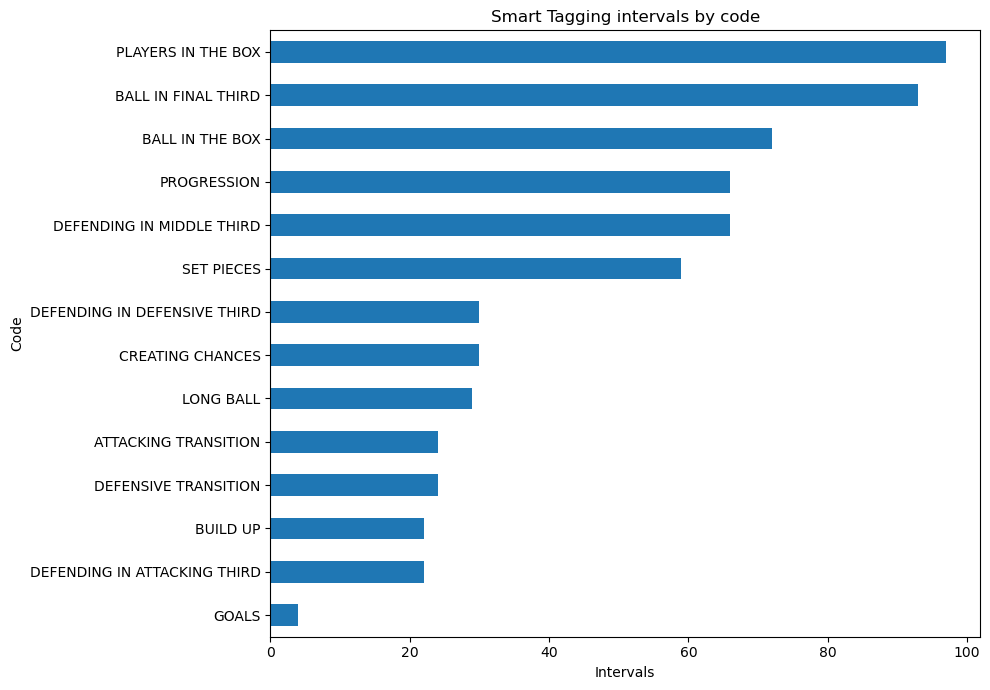

In [4]:
code_counts = events['code'].value_counts().sort_values()
display(code_counts.rename('intervals').to_frame())

ax = code_counts.plot.barh(figsize=(10, 7), title='Smart Tagging intervals by code')
ax.set_xlabel('Intervals')
ax.set_ylabel('Code')
plt.tight_layout()
plt.show()

## 3. Team, half and tag-value distributions

Missing values are expected because not every tag group applies to every code. `N/A` is also a real tag value and must not silently become Home or Away.

In [5]:
categorical_columns = [
    column for column in ['Team', 'Half', 'Type', 'Side',
                          'Direction of ball entry', 'Max Players in the box']
    if column in events.columns
]
for column in categorical_columns:
    print(f'\n{column}')
    display(events[column].value_counts(dropna=False).rename('count').to_frame())


Team


,count
Team,
Barcelona,314
Atletic Club,288
N/A,36



Half


,count
Half,
1st Half,320
2nd Half,318



Type


,count
Type,
NaN,579
Throw-in,26
Corner Kick,12
Goal Kick,10
Free Kick,5
Kick Off (After Goal),4
Kick Off (Start),2


... (2 outputs left out)


Direction of ball entry


,count
Direction of ball entry,
NaN,566
Horizontal,34
Vertical,25
Diagonal,13



Max Players in the box


,count
Max Players in the box,
NaN,376
4,65
1,59
2,43
5,31
6,27
3,27
7+,10


Team,Atletic Club,Barcelona,N/A
code,,,
ATTACKING TRANSITION,11,13,0
BALL IN FINAL THIRD,39,54,0
BALL IN THE BOX,30,42,0
BUILD UP,7,15,0
CREATING CHANCES,9,19,2
DEFENDING IN ATTACKING THIRD,15,7,0
DEFENDING IN DEFENSIVE THIRD,19,9,2
DEFENDING IN MIDDLE THIRD,47,19,0
DEFENSIVE TRANSITION,13,11,0


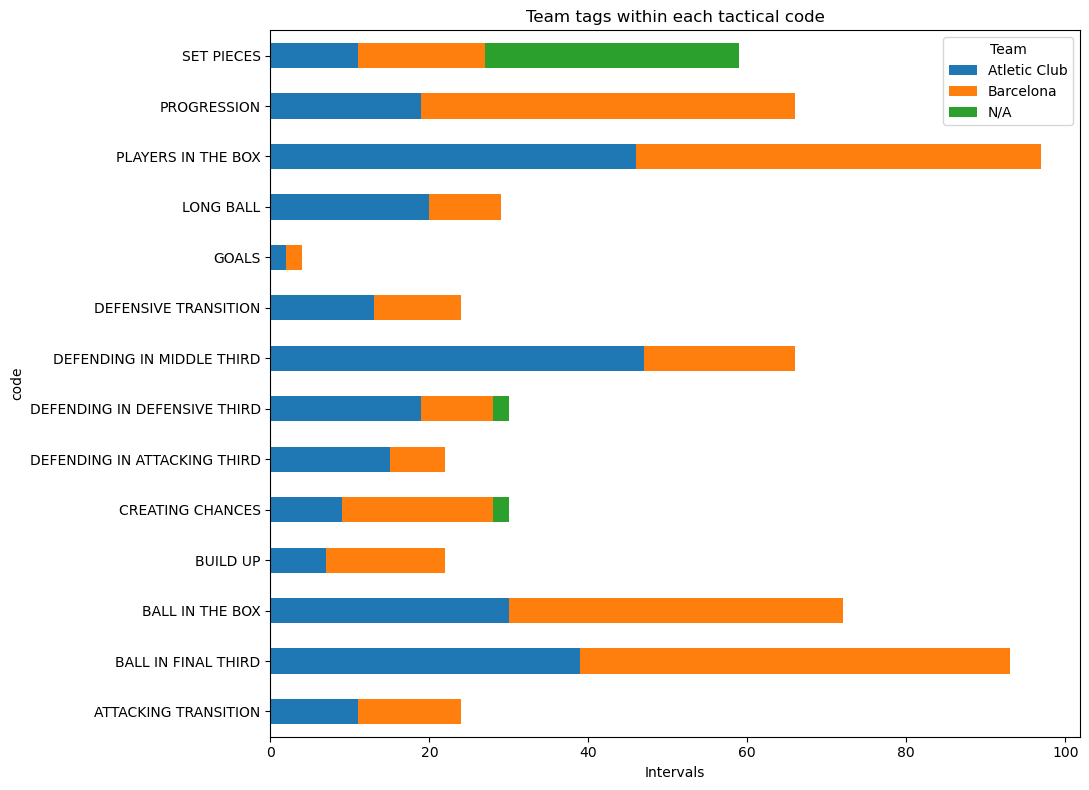

In [6]:
if 'Team' in events.columns:
    team_by_code = pd.crosstab(events['code'], events['Team'], dropna=False)
    display(team_by_code)
    team_by_code.plot.barh(stacked=True, figsize=(11, 8), title='Team tags within each tactical code')
    plt.xlabel('Intervals')
    plt.tight_layout()
    plt.show()

## 4. Interval-duration distributions

Smart Tagging intervals are windows, not exact possession or restart boundaries. Their duration distributions help show which codes describe long phases and which describe short events.

In [7]:
duration_summary = events.groupby('code')['duration_s'].agg(
    intervals='size', minimum='min', median='median', mean='mean', maximum='max'
).sort_values('intervals', ascending=False)
display(duration_summary.round(2))

,intervals,minimum,median,mean,maximum
code,,,,,
PLAYERS IN THE BOX,97,17.12,27.68,35.51,83.68
BALL IN FINAL THIRD,93,20.60,27.00,30.11,70.84
BALL IN THE BOX,72,15.24,17.44,18.10,32.48
DEFENDING IN MIDDLE THIRD,66,7.68,17.64,18.86,37.08
PROGRESSION,66,7.68,17.64,18.86,37.08
SET PIECES,59,5.00,35.00,31.95,35.00
CREATING CHANCES,30,30.00,30.00,30.00,30.00
DEFENDING IN DEFENSIVE THIRD,30,30.00,30.00,30.00,30.00
LONG BALL,29,8.08,12.40,13.15,22.20


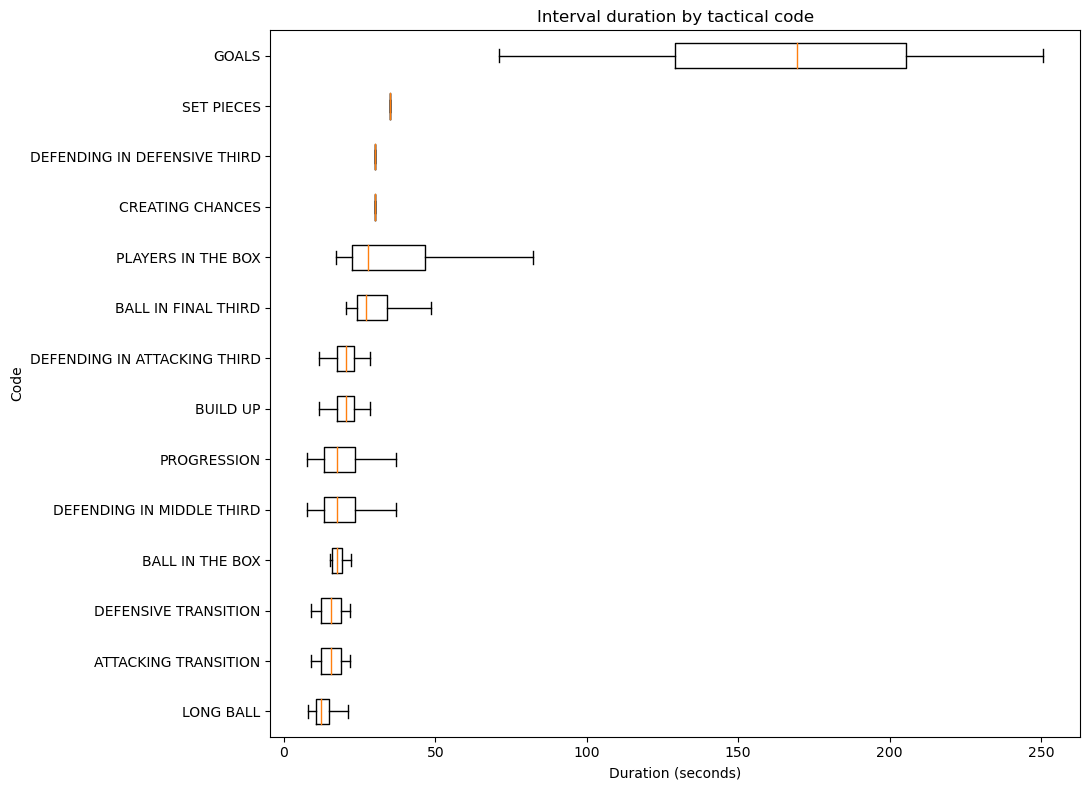

In [8]:
ordered_codes = duration_summary.sort_values('median').index.tolist()
values = [events.loc[events['code'] == code, 'duration_s'].to_numpy() for code in ordered_codes]
fig, ax = plt.subplots(figsize=(11, 8))
ax.boxplot(values, labels=ordered_codes, vert=False, showfliers=False)
ax.set(title='Interval duration by tactical code', xlabel='Duration (seconds)', ylabel='Code')
fig.tight_layout()
plt.show()

## 5. Set pieces

Set-piece intervals are particularly useful as approximate restart evidence for the dead-ball state. They should not be treated as exact restart frames.

In [9]:
set_pieces = events[events['code'].str.casefold() == 'set pieces'].copy()
columns = [c for c in ['Half', 'Team', 'Type', 'start_s', 'end_s', 'duration_s',
                         'start_frame', 'end_frame'] if c in set_pieces.columns]
display(set_pieces[columns].head(20))
if 'Type' in set_pieces.columns:
    display(set_pieces['Type'].value_counts(dropna=False).rename('count').to_frame())

,Half,Team,Type,start_s,end_s,duration_s,start_frame,end_frame
2,1st Half,N/A,Kick Off (Start),443.88,448.88,5.0,11097,11222
22,1st Half,Atletic Club,Free Kick,701.32,736.32,35.0,17533,18408
27,1st Half,Barcelona,Goal Kick,732.80,767.80,35.0,18320,19195
31,1st Half,N/A,Throw-in,781.40,816.40,35.0,19535,20410
35,1st Half,N/A,Throw-in,863.04,898.04,35.0,21576,22451
59,1st Half,N/A,Throw-in,1016.40,1051.40,35.0,25410,26285
71,1st Half,N/A,Throw-in,1111.76,1146.76,35.0,27794,28669
79,1st Half,Barcelona,Corner Kick,1184.32,1219.32,35.0,29608,30483
96,1st Half,Barcelona,Corner Kick,1386.04,1421.04,35.0,34651,35526
109,1st Half,Atletic Club,Corner Kick,1477.56,1512.56,35.0,36939,37814


,count
Type,
Throw-in,26
Corner Kick,12
Goal Kick,10
Free Kick,5
Kick Off (After Goal),4
Kick Off (Start),2


## 6. When do the intervals occur?

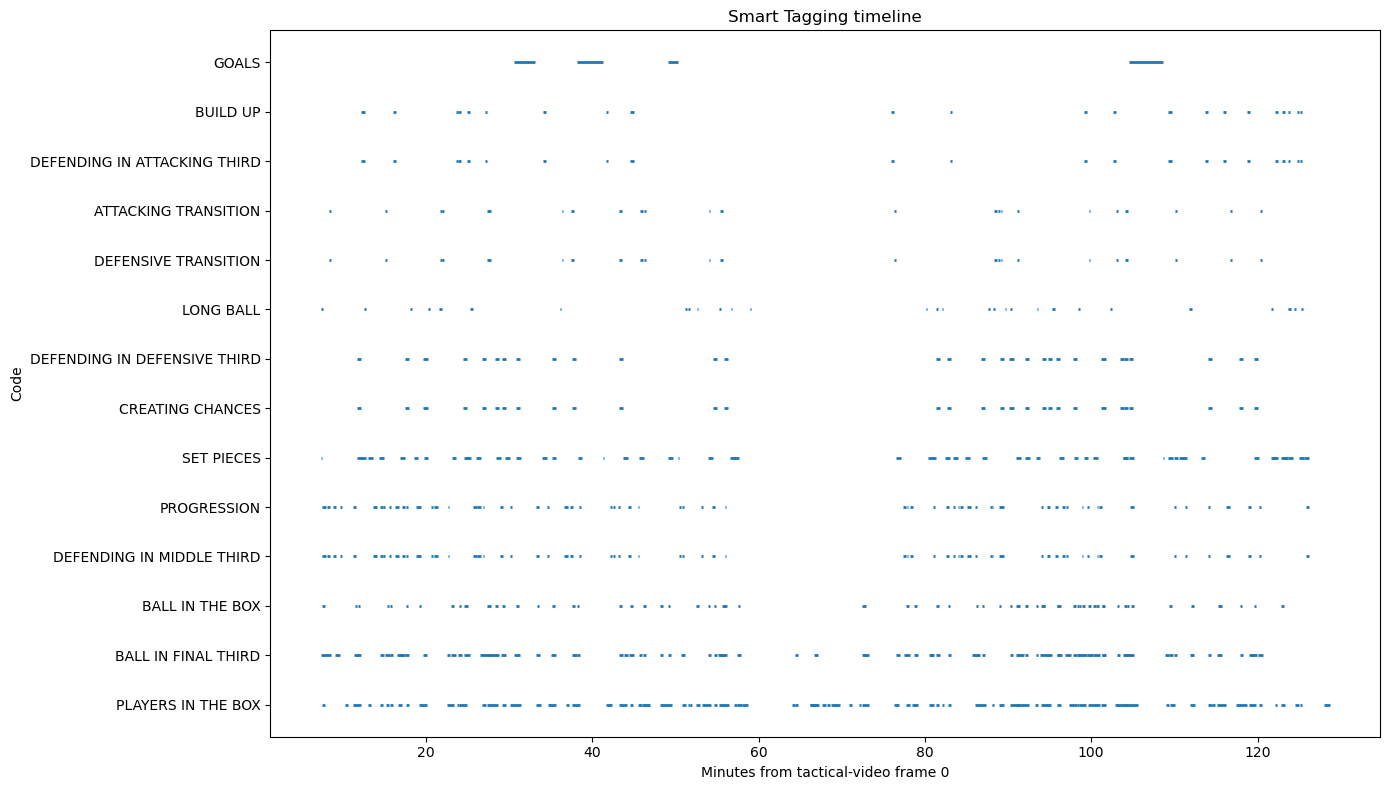

In [10]:
code_order = events['code'].value_counts().index.tolist()
code_to_y = {code: i for i, code in enumerate(code_order)}
fig, ax = plt.subplots(figsize=(14, 8))
for code, group in events.groupby('code'):
    y = code_to_y[code]
    ax.hlines(np.full(len(group), y), group['start_s'] / 60, group['end_s'] / 60, linewidth=2)
ax.set_yticks(range(len(code_order)), code_order)
ax.set(title='Smart Tagging timeline', xlabel='Minutes from tactical-video frame 0', ylabel='Code')
fig.tight_layout()
plt.show()

## What Person 1 should export

Convert intervals into frame-aligned indicator columns such as `set_piece_active`, `smart_tag_home`, `smart_tag_away`, and selected code flags. Preserve an explicit `N/A`/missing flag. Do not copy team tags directly into final possession labels: phases are approximate and can span different possession situations.

---

**Before committing:** restart the kernel, clear every output, and save.